    ## CREDIT  CARD ANALYSIS ##

                ## IMPORT  DATASET FROM KAGGLE##


In [ ]:
 import kagglehub

# Download latest version
path = kagglehub.dataset_download("miadul/credit-card-fraud-detection-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'credit-card-fraud-detection-dataset' dataset.
Path to dataset files: /kaggle/input/credit-card-fraud-detection-dataset


In [ ]:
import pandas as pd

# The dataset seems to be a CSV file. Let's list the files in the downloaded path to confirm.
import os
csv_file = [f for f in os.listdir(path) if f.endswith('.csv')][0]
df = pd.read_csv(os.path.join(path, csv_file))

df.head()


,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0


In [ ]:
# there is 10 features(columns) out of 10 only merchant_category is categroical
# 9 are numerical
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   transaction_id       10000 non-null  int64  
 1   amount               10000 non-null  float64
 2   transaction_hour     10000 non-null  int64  
 3   merchant_category    10000 non-null  object 
 4   foreign_transaction  10000 non-null  int64  
 5   location_mismatch    10000 non-null  int64  
 6   device_trust_score   10000 non-null  int64  
 7   velocity_last_24h    10000 non-null  int64  
 8   cardholder_age       10000 non-null  int64  
 9   is_fraud             10000 non-null  int64  
dtypes: float64(1), int64(8), object(1)
memory usage: 781.4+ KB


In [ ]:
# this will tell us aboout the described statictics
df.describe()

,transaction_id,amount,transaction_hour,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,175.949849,11.593300,0.097800,0.085700,61.798900,2.008900,43.468700,0.015100
std,2886.89568,175.392827,6.922708,0.297059,0.279935,21.487053,1.432559,14.979147,0.121957
min,1.00000,0.000000,0.000000,0.000000,0.000000,25.000000,0.000000,18.000000,0.000000
25%,2500.75000,50.905000,6.000000,0.000000,0.000000,43.000000,1.000000,30.000000,0.000000
50%,5000.50000,122.095000,12.000000,0.000000,0.000000,62.000000,2.000000,44.000000,0.000000
75%,7500.25000,242.480000,18.000000,0.000000,0.000000,80.000000,3.000000,56.000000,0.000000
max,10000.00000,1471.040000,23.000000,1.000000,1.000000,99.000000,9.000000,69.000000,1.000000


In [ ]:
df.shape
# here we have 10000 rows and 10 column

(10000, 10)

## 3. Exploratory Data Analysis (EDA)

We explore the data in the standard order every ML engineer follows:

* Missing values
* Univariate analysis (one variable at a time – distributions, skewness)
* Bivariate analysis (relationship between features and the target)
* Correlation between numeric features
* Outlier inspection

In [ ]:
#3.1lets check the missing value
#here we check that there is no missing value in our dataset
df.isnull().sum()

,0
transaction_id,0
amount,0
transaction_hour,0
merchant_category,0
foreign_transaction,0
location_mismatch,0
device_trust_score,0
velocity_last_24h,0
cardholder_age,0
is_fraud,0


<Axes: xlabel='is_fraud', ylabel='count'>

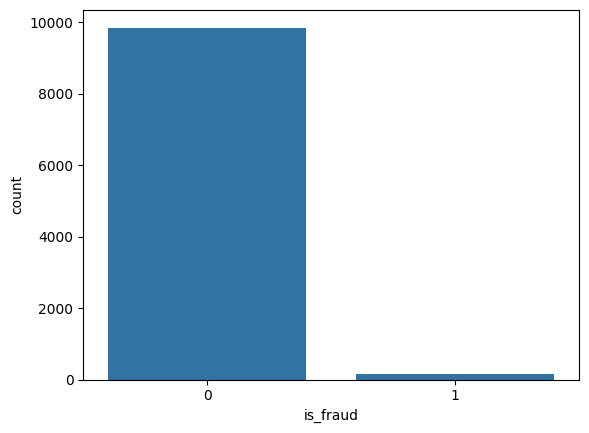

In [ ]:

 # lets check the distribution of the target column  there is case of imbalance dataset
df['is_fraud'].value_counts()
# so here there is no case of baise and imbalanceed dataset
# esme kya hota h apka machine learing  model ek chej pe jadya perfrom karta h aur dushre pe kam
import seaborn as sns
sns.countplot(x='is_fraud', data=df)


In [ ]:
#3.2 univariate analysis - on numerical features
numericals_columns= df.columns[df.dtypes != 'object'].drop('transaction_id')
numericals_columns

Index(['amount', 'transaction_hour', 'foreign_transaction',
       'location_mismatch', 'device_trust_score', 'velocity_last_24h',
       'cardholder_age', 'is_fraud'],
      dtype='object')

array([[<Axes: title={'center': 'amount'}>,
        <Axes: title={'center': 'transaction_hour'}>,
        <Axes: title={'center': 'foreign_transaction'}>],
       [<Axes: title={'center': 'location_mismatch'}>,
        <Axes: title={'center': 'device_trust_score'}>,
        <Axes: title={'center': 'velocity_last_24h'}>],
       [<Axes: title={'center': 'cardholder_age'}>,
        <Axes: title={'center': 'is_fraud'}>, <Axes: >]], dtype=object)

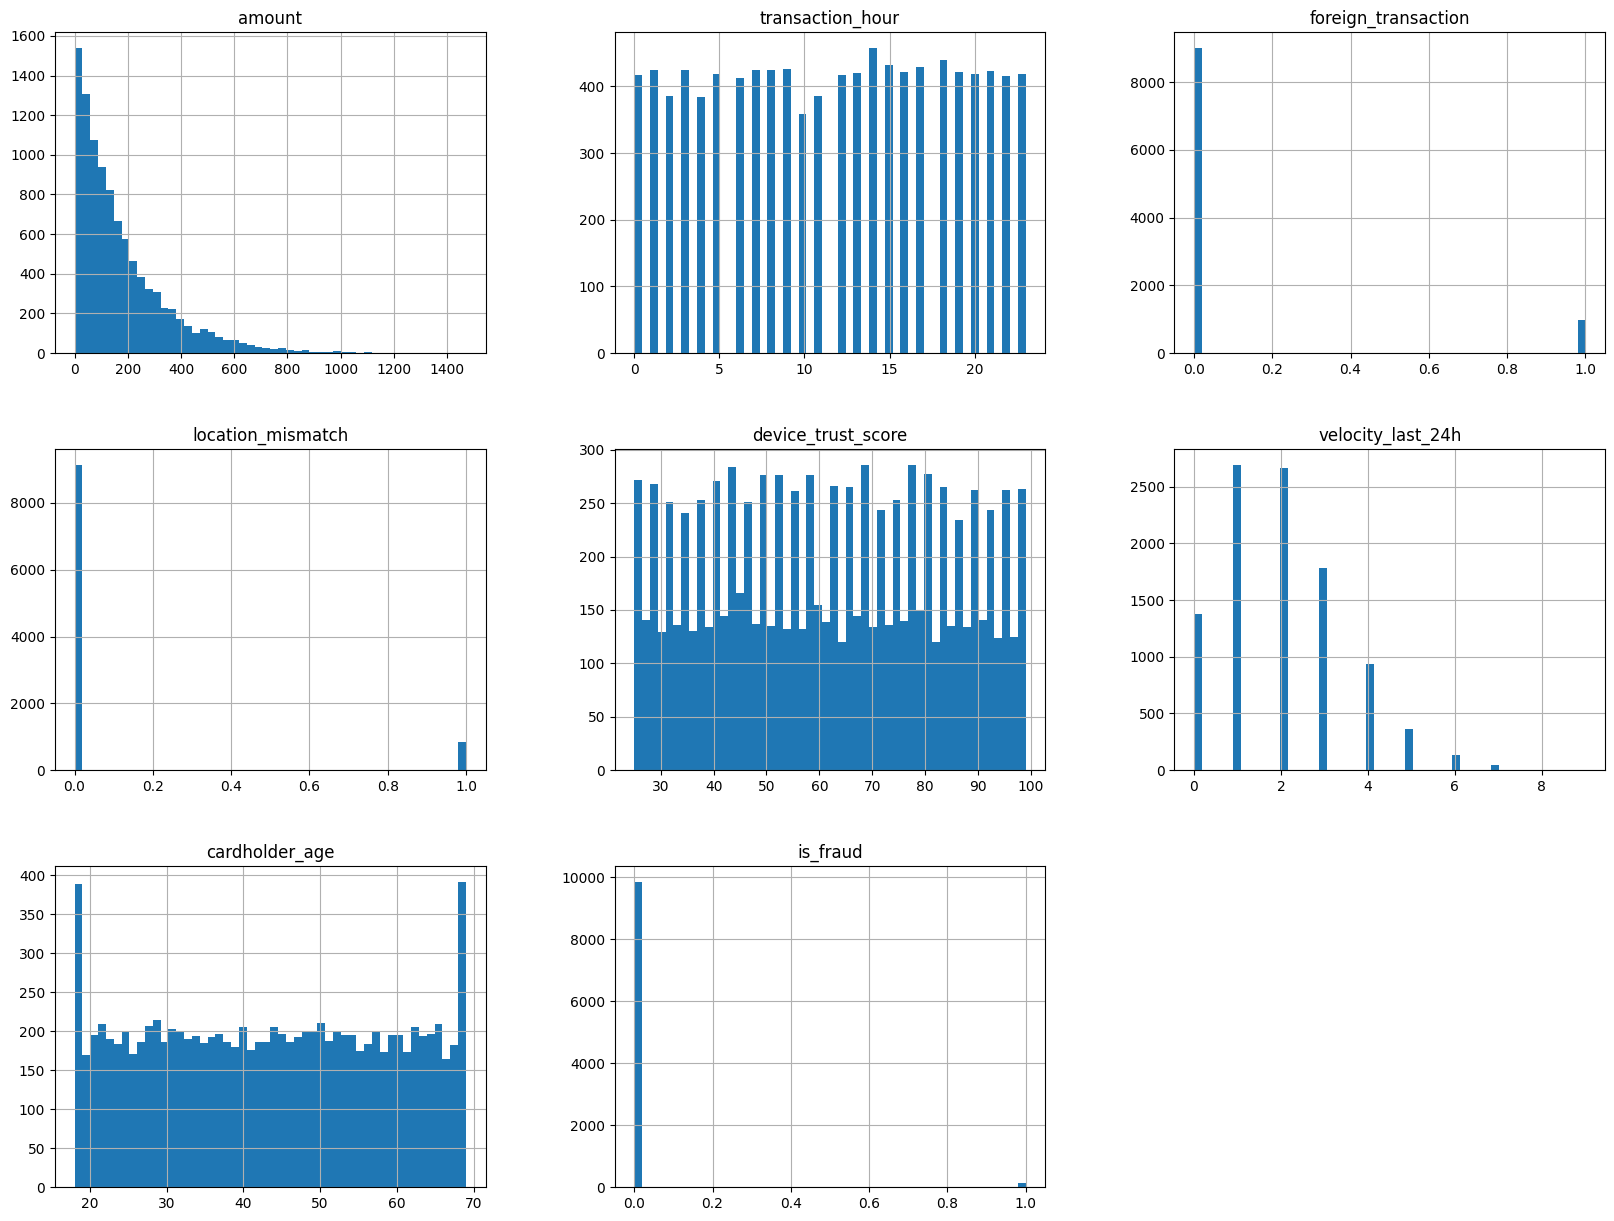

In [ ]:
# lets check  value count(hist )  by graph
df[numericals_columns].hist(bins=50, figsize=(20,15))

<Axes: xlabel='merchant_category', ylabel='count'>

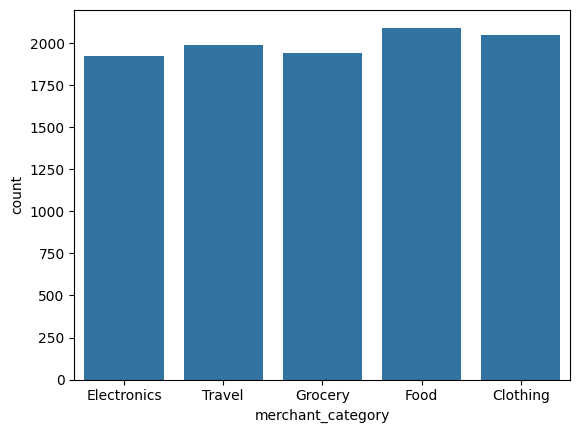

In [ ]:

#3. lets create the countplot of the categorical colummns
sns.countplot(x="merchant_category", data=df )

<Axes: xlabel='merchant_category', ylabel='amount'>

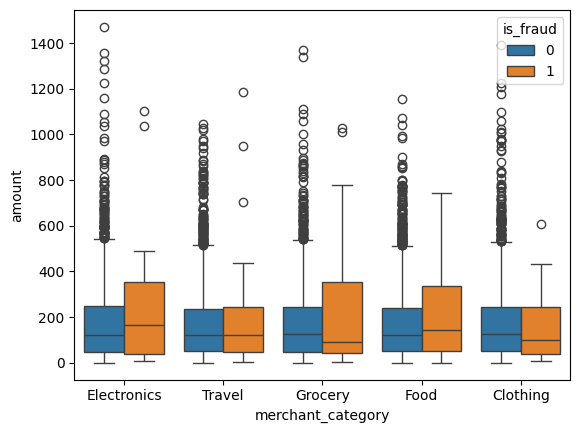

In [ ]:
#3. lets do bivarite analysis  - target colunn and merchant_categroy
sns.boxplot(x='merchant_category', y='amount', hue='is_fraud', data=df)

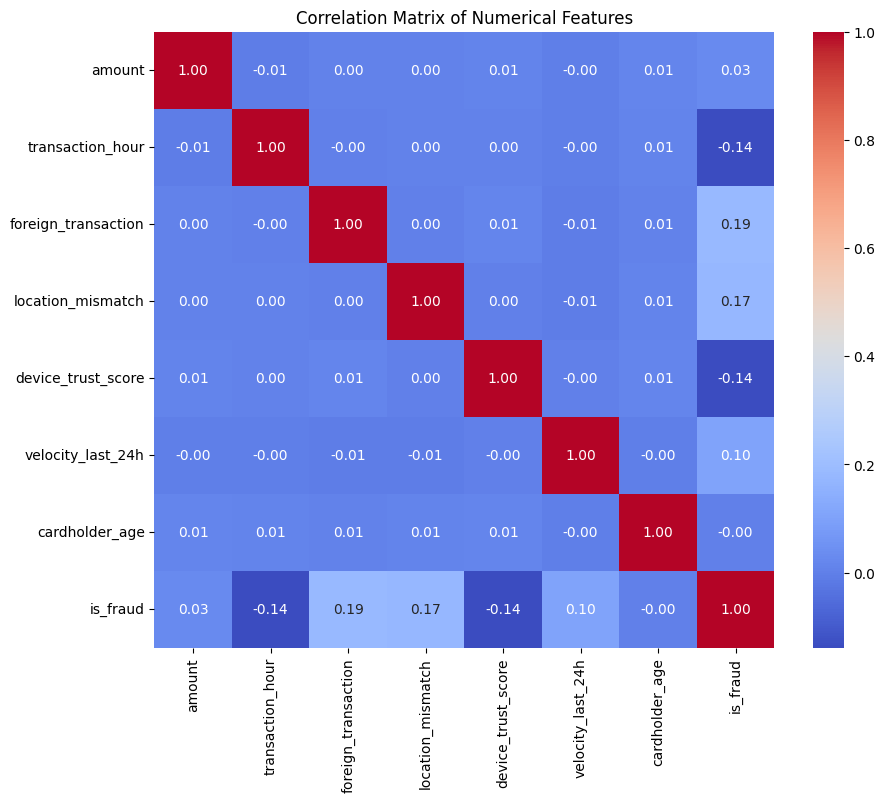

In [ ]:
# 3. lets find the co-relation between our numeric features cor
import matplotlib.pyplot as plt

# Ensure 'numericals_columns' is defined and contains the correct column names
# Based on previous steps, 'numericals_columns' is already an Index of numerical column names
core = df[numericals_columns].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(core, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numerical Features')
plt.show()

## 4. Data Cleaning & Feature Engineering

1. we deal with missing value but in our case there is no missing value
2. know we deal with the outlier by inter quantile range  
3. do feature selection at last



In [ ]:
df_clean= df.drop(columns ='transaction_id')

In [ ]:
#4.1 we have no missing value in our dataset
df_clean.isnull().sum()

,0
amount,0
transaction_hour,0
merchant_category,0
foreign_transaction,0
location_mismatch,0
device_trust_score,0
velocity_last_24h,0
cardholder_age,0
is_fraud,0


In [ ]:
# know the time to handle the outliers
# method 1 clip the outlier in a given range
# method 2 if the outlier was very  small then we drop our outlier


In [ ]:
import numpy as np

# Columns to apply clipping on (excluding binary and transaction_id/is_fraud)
columns_to_clip = ['amount', 'transaction_hour', 'device_trust_score', 'velocity_last_24h', 'cardholder_age']

# Apply clipping directly to df_clean
for col in columns_to_clip:
    lower_bound = df_clean[col].quantile(0.01)
    upper_bound = df_clean[col].quantile(0.99)
    df_clean[col] = np.clip(df_clean[col], lower_bound, upper_bound)
    print(f"Clipped '{col}': Lower bound {lower_bound:.2f}, Upper bound {upper_bound:.2f}")

print("\nDataFrame head after permanent outlier clipping:")
display(df_clean.head())

Clipped 'amount': Lower bound 1.94, Upper bound 796.32
Clipped 'transaction_hour': Lower bound 0.00, Upper bound 23.00
Clipped 'device_trust_score': Lower bound 25.00, Upper bound 99.00
Clipped 'velocity_last_24h': Lower bound 0.00, Upper bound 6.00
Clipped 'cardholder_age': Lower bound 18.00, Upper bound 69.00

DataFrame head after permanent outlier clipping:


,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,84.47,22,Electronics,0,0,66,3,40,0
1,541.82,3,Travel,1,0,87,1,64,0
2,237.01,17,Grocery,0,0,49,1,61,0
3,164.33,4,Grocery,0,1,72,3,34,0
4,30.53,15,Food,0,0,79,0,44,0


In [ ]:
x=df_clean.drop(columns='is_fraud')
y = df_clean['is_fraud']

# after separating the data we cannot direct apply data preprocissing step
# it may increase the chances of dataleakage so we used these step in pipeline and transfromer to avoid this
df_clean[numericals_columns].skew()

,0
amount,1.543433
transaction_hour,-0.026581
foreign_transaction,2.708422
location_mismatch,2.960570
device_trust_score,0.011191
velocity_last_24h,0.600544
cardholder_age,0.003868
is_fraud,7.953582


 5...                    **train test split**
 1 we have many problem which we have faced during the split these is a big issue of basisness  so we used the concept of stratisfy to overcome with the problem and maintain the ratio in our dataset



In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y ,test_size= 0.33 , random_state = 42,stratify=y)

In [ ]:
## stratify ye ensure karta h ke jab bhi hum split kare ya sample kare toh har group ya class ka original proportion ho

## 6. Preprocessing: ColumnTransformer + Pipeline

Production ML code should never manually transform train/test data with separate lines — it's error-prone and leaks information. Instead, we build a single, reusable ColumnTransformer:

Numeric features → median imputation + standard scaling
###
Categorical features → most-frequent imputation + one-hot encoding

This transformer will be the first step of every model pipeline below, so preprocessing is learned only on training data and applied consistently everywhere (no data leakage)

In [ ]:
# there are many encoding techinque used in  depending upon the column  it may be label encoder , one hot encoder , normal encoder

In [ ]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,OneHotEncoder, PowerTransformer
from sklearn.impute import SimpleImputer

# Redefine numerical and categorical columns based on the feature set `x`
numericals_columns = x.select_dtypes(include=np.number).columns
categorical_columns = x.select_dtypes(include='object').columns

 #1 for numerical column
numeric_pipeline = Pipeline(steps=[ ('scaler', StandardScaler())])

 # for categorical column
categorical_pipeline = Pipeline(steps=[('onehot', OneHotEncoder(handle_unknown='ignore'))])

In [ ]:
#apply column transfromer
from sklearn.compose import ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_pipeline, numericals_columns),
        ('cat', categorical_pipeline, categorical_columns)
    ])
preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('scaler', StandardScaler())]),
                                 Index(['amount', 'transaction_hour', 'foreign_transaction',
       'location_mismatch', 'device_trust_score', 'velocity_last_24h',
       'cardholder_age'],
      dtype='object')),
                                ('cat',
                                 Pipeline(steps=[('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 Index(['merchant_category'], dtype='object'))])

# 8 Trying multiple Algorithms
 we now compare the severals model ,each wrapped in its pipeline with the same processor . we evaluate each with 3 fold cross validation on the traing set
 ## 1.logistic regression - simple ,interpretable linear baseline
 ## 2.decision tree -a single non-linear model, porn to overfitting
 ## 3. Random forest - a an essemble techinuque used in  bagging technique
 ## 4. gradinet boosting - it was a boosting techinque


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report

In [ ]:
# know we  want to solved the class imbalanced
# 1 we use SMOTE to solved this problem (fake  values generate in the minority class)
## disad - 1 . high chance of overfitting 2. data leakage
# 2. we also used the class weight parameter that was in build in our many models

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# class_weight='balanced'  tells us the model to pay more attention to the minority class

models={
    "Logistic Regression ": LogisticRegression(class_weight="balanced", random_state=42),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(class_weight="balanced", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
    }

In [ ]:
from sklearn.pipeline import Pipeline

for name, model in models.items():
  pipe = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", model)])

  accuracy = cross_val_score(pipe, x_train, y_train, cv=3, scoring="accuracy")
  macrof1 = cross_val_score(pipe, x_train, y_train, scoring="f1_macro")

  print(f"{name} -> {{'Accuracy': {accuracy.mean():.3f}, 'F1': {macrof1.mean():.3f}}}")

Logistic Regression  -> {'Accuracy': 0.961, 'F1': 0.704}
Decision Tree -> {'Accuracy': 0.993, 'F1': 0.899}
Random Forest -> {'Accuracy': 0.990, 'F1': 0.759}
Gradient Boosting -> {'Accuracy': 0.997, 'F1': 0.970}


# hyperparameter tunning
 know we pick our best model and know it was time to hyperparameter tunning the model

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline # Ensure Pipeline is imported for clarity
from sklearn.ensemble import RandomForestClassifier # Ensure RandomForestClassifier is imported

best_pipeline=Pipeline(steps=[("preprocessor",preprocessor),("classifier",RandomForestClassifier(class_weight='balanced') )])


param_distribution={
    "classifier__n_estimators":[100,200,300],
    "classifier__max_depth":[8,12,18,None], # Corrected 'max_dept' to 'max_depth' and 'none' to 'None'
    "classifier__min_samples_split":[2,5,10]
}

# Corrected GridSearchCV call: added param_grid keyword, removed invalid n_iters
search = GridSearchCV(estimator=best_pipeline, param_grid=param_distribution, cv=3, scoring="f1_macro")
search.fit(x_train,y_train)

GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('scaler',
                                                                                          StandardScaler())]),
                                                                         Index(['amount', 'transaction_hour', 'foreign_transaction',
       'location_mismatch', 'device_trust_score', 'velocity_last_24h',
       'cardholder_age'],
      dtype='object')),
                                                                        ('cat',
                                                                         Pipeline(steps=[('onehot',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         Index(['merchant_category'], dtype='object'))])),
                                       ('classifier',
                                        RandomForestClassifier(class_weight='balanced'))]),
             param_grid={'classifier__max_depth': [8, 12, 18, None],
                         'classifier__min_samples_split': [2, 5, 10],
                         'classifier__n_estimators': [100, 200, 300]},
             scoring='f1_macro')

In [ ]:
print("bestparms",search.best_params_)

bestparms {'classifier__max_depth': 8, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 200}


In [ ]:
best_model = search.best_estimator_

print("Checking fitted model...")

predictions = best_model.predict(x_test)

print("SUCCESS")
print(predictions[:10])

Checking fitted model...
SUCCESS
[0 0 0 0 0 0 0 0 0 0]


#LAST STAGE  
 in production the entire pipeline is serailized as a single  so a new listing can be scored with one call no manual preprocessing required at inference time



In [ ]:
import joblib

best_model = search.best_estimator_

joblib.dump(best_model, "model_pipeline17.pkl")

print("Model saved successfully!")

Model saved successfully!
